In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

data = fetch_ucirepo(id=601)
df = pd.concat([data.data.features, data.data.targets], axis=1)
print(df.shape)
df.head()

ModuleNotFoundError: No module named 'ucimlrepo'

In [1]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn shap joblib


  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached ucimlrepo-0.0.7-py3-none-any.whl (8.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ---------- ----------------------------- 1/4 [xgboost]
   ------------------------------ --------

In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

data = fetch_ucirepo(id=601)
df = pd.concat([data.data.features, data.data.targets], axis=1)
print(df.shape)
df.head()

(10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print(df.columns.tolist())

['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [3]:
df.columns = ["UID","product_id","type","air_temp","process_temp",
              "rpm","torque","tool_wear","failure","TWF","HDF","PWF","OSF","RNF"]

ValueError: Length mismatch: Expected axis has 12 elements, new values have 14 elements

In [4]:
df = df.rename(columns={
    "Product ID": "product_id", "Type": "type",
    "Air temperature": "air_temp", "Process temperature": "process_temp",
    "Rotational speed": "rpm", "Torque": "torque", "Tool wear": "tool_wear",
    "Machine failure": "failure"
})

In [5]:
print(df.info())                       # types and missing values
print(df.describe())                   # basic statistics
print(df["failure"].value_counts())    # class balance
print(df["failure"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   type          10000 non-null  object 
 1   air_temp      10000 non-null  float64
 2   process_temp  10000 non-null  float64
 3   rpm           10000 non-null  int64  
 4   torque        10000 non-null  float64
 5   tool_wear     10000 non-null  int64  
 6   failure       10000 non-null  int64  
 7   TWF           10000 non-null  int64  
 8   HDF           10000 non-null  int64  
 9   PWF           10000 non-null  int64  
 10  OSF           10000 non-null  int64  
 11  RNF           10000 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 937.6+ KB
None
           air_temp  process_temp           rpm        torque     tool_wear  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean     300.004930    310.005560   1538.776100     39.986910  

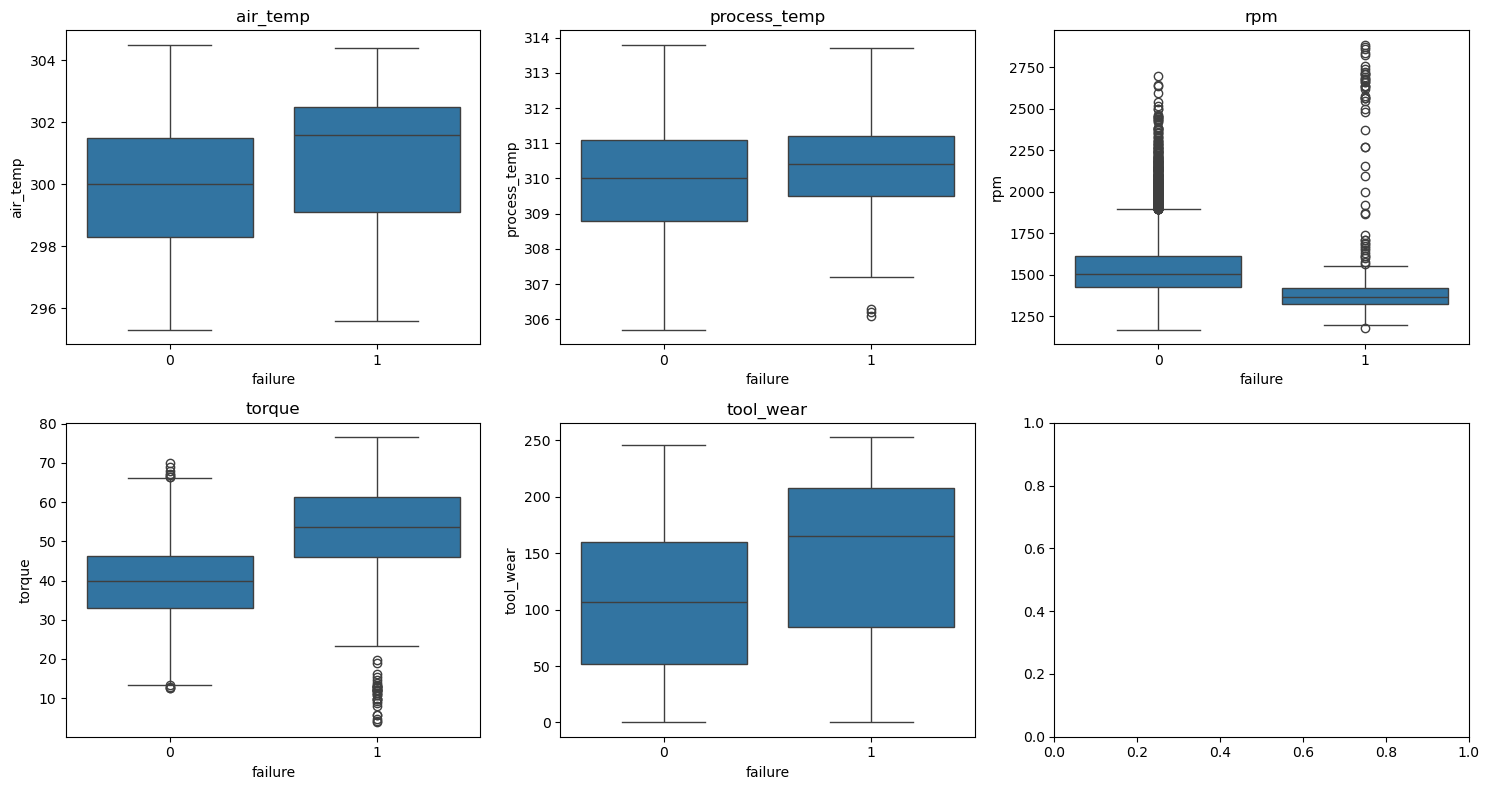

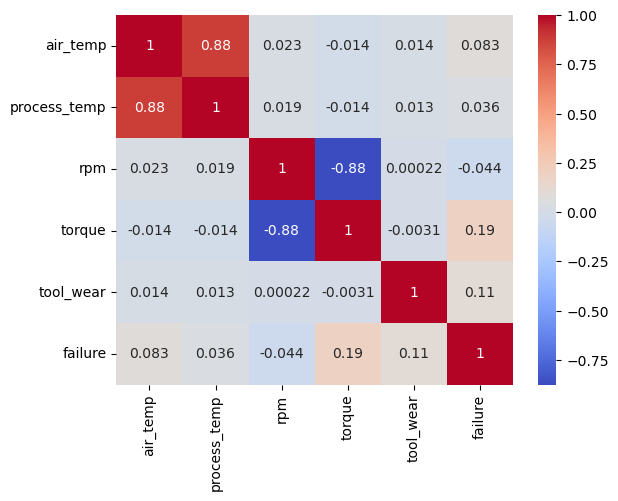

type
H    0.020937
L    0.039167
M    0.027694
Name: failure, dtype: float64


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="failure", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

sns.heatmap(df[num_cols + ["failure"]].corr(), annot=True, cmap="coolwarm")
plt.show()

print(df.groupby("type")["failure"].mean())   # failure rate per quality type

In [7]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rpm"] * 2 * 3.1416 / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]
df = pd.get_dummies(df, columns=["type"], drop_first=True, dtype=int)
df.head()

,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF,temp_diff,power,wear_torque,type_L,type_M
0,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.606816,0.0,0,1
1,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.738688,138.9,1,0
2,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.405664,247.0,1,0
3,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.518520,276.5,1,0
4,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.830400,360.0,1,0


In [8]:
drop_cols = ["UID", "product_id", "failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df["failure"]
print(X.columns.tolist())

['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'temp_diff', 'power', 'wear_torque', 'type_L', 'type_M']


In [9]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(y_tr.mean(), y_te.mean())   # both should be about 0.034

0.033875 0.034


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, average_precision_score

base = make_pipeline(StandardScaler(),
                     LogisticRegression(class_weight="balanced", max_iter=1000))
base.fit(X_tr, y_tr)
p_base = base.predict_proba(X_te)[:, 1]
print("Baseline PR-AUC:", average_precision_score(y_te, p_base))
print(classification_report(y_te, base.predict(X_te)))

Baseline PR-AUC: 0.42953655404136826
              precision    recall  f1-score   support

           0       1.00      0.86      0.92      1932
           1       0.18      0.88      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.87      0.61      2000
weighted avg       0.97      0.86      0.90      2000



In [11]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

spw = (y_tr == 0).sum() / (y_tr == 1).sum()

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                    scale_pos_weight=spw, eval_metric="logloss", random_state=42)
rf.fit(X_tr, y_tr)
xgb.fit(X_tr, y_tr)

for name, m in [("RandomForest", rf), ("XGBoost", xgb)]:
    p = m.predict_proba(X_te)[:, 1]
    print(name, "PR-AUC:", round(average_precision_score(y_te, p), 4))

RandomForest PR-AUC: 0.8788
XGBoost PR-AUC: 0.8836


In [12]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_rf = ImbPipeline([("smote", SMOTE(random_state=42)),
                        ("clf", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))])
smote_rf.fit(X_tr, y_tr)
print("SMOTE+RF PR-AUC:", average_precision_score(y_te, smote_rf.predict_proba(X_te)[:, 1]))

SMOTE+RF PR-AUC: 0.8225155288131784


In [ ]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
    param_dist, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=42, verbose=1)
search.fit(X_tr, y_tr)

best = search.best_estimator_
print("Best params:", search.best_params_)
print("CV PR-AUC:", round(search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits


In [1]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

p_cv = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, p_cv)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
threshold = thr[np.argmax(f1[:-1])]
print("Chosen threshold:", round(threshold, 3))

NameError: name 'best' is not defined

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

p_te = best.predict_proba(X_te)[:, 1]
pred = (p_te >= threshold).astype(int)

print("Test PR-AUC:", round(average_precision_score(y_te, p_te), 4))
print(classification_report(y_te, pred, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred)).plot()
plt.show()

In [2]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from xgboost import XGBClassifier

# Load (use the CSV in the same folder as your notebook)
df = pd.read_csv("ai4i2020.csv")
df.columns = ["UID","product_id","type","air_temp","process_temp",
              "rpm","torque","tool_wear","failure","TWF","HDF","PWF","OSF","RNF"]

# Feature engineering
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rpm"] * 2 * 3.1416 / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]
df = pd.get_dummies(df, columns=["type"], drop_first=True, dtype=int)

# Features and target
drop_cols = ["UID","product_id","failure","TWF","HDF","PWF","OSF","RNF"]
X = df.drop(columns=drop_cols)
y = df["failure"]

# Split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

# Tune (Step 11)
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
    param_dist, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=42, verbose=1)
search.fit(X_tr, y_tr)

best = search.best_estimator_
print("Best params:", search.best_params_)
print("CV PR-AUC:", round(search.best_score_, 4))

FileNotFoundError: [Errno 2] No such file or directory: 'ai4i2020.csv'

In [3]:
import pandas as pd, numpy as np
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=601)
df = pd.concat([data.data.features, data.data.targets], axis=1)

# Remove units like [K], [rpm], [Nm], [min] from column names, then rename
df = df.rename(columns=lambda c: c.split("[")[0].strip())
df = df.rename(columns={
    "Product ID": "product_id", "Type": "type",
    "Air temperature": "air_temp", "Process temperature": "process_temp",
    "Rotational speed": "rpm", "Torque": "torque", "Tool wear": "tool_wear",
    "Machine failure": "failure"
})
print(df.columns.tolist())
print(df.shape)

['type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
(10000, 12)


In [4]:
drop_cols = ["UID","product_id","failure","TWF","HDF","PWF","OSF","RNF"]
X = df.drop(columns=drop_cols, errors="ignore")
y = df["failure"]

In [5]:
import os
print(os.getcwd())

C:\Users\subhr


In [6]:
df = pd.read_csv(r"C:\Users\YourName\Downloads\ai4i2020.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\YourName\\Downloads\\ai4i2020.csv'

In [7]:
%pip install ucimlrepo -q

import pandas as pd
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=601)
df = pd.concat([data.data.features, data.data.targets], axis=1)

# Remove units like [K], [rpm] from names, then rename
df = df.rename(columns=lambda c: c.split("[")[0].strip())
df = df.rename(columns={
    "Product ID": "product_id", "Type": "type",
    "Air temperature": "air_temp", "Process temperature": "process_temp",
    "Rotational speed": "rpm", "Torque": "torque", "Tool wear": "tool_wear",
    "Machine failure": "failure"
})

print(df.shape)
print(df.columns.tolist())
df.head()

Note: you may need to restart the kernel to use updated packages.
(10000, 12)
['type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [8]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from xgboost import XGBClassifier

# Feature engineering
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rpm"] * 2 * 3.1416 / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]
df = pd.get_dummies(df, columns=["type"], drop_first=True, dtype=int)

# Features and target
drop_cols = ["UID","product_id","failure","TWF","HDF","PWF","OSF","RNF"]
X = df.drop(columns=drop_cols, errors="ignore")
y = df["failure"]

# Split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

# Tune
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
    param_dist, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=42, verbose=1)
search.fit(X_tr, y_tr)

best = search.best_estimator_
print("Best params:", search.best_params_)
print("CV PR-AUC:", round(search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best params: {'subsample': 1.0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.85}
CV PR-AUC: 0.8656


In [9]:
print(best is not None, X_tr.shape, X_te.shape)

True (8000, 10) (2000, 10)


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

p_cv = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, p_cv)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
threshold = thr[np.argmax(f1[:-1])]
print("Chosen threshold:", round(threshold, 3))

Chosen threshold: 0.854


Test PR-AUC: 0.9073
              precision    recall  f1-score   support

           0      0.993     0.997     0.995      1932
           1      0.917     0.809     0.859        68

    accuracy                          0.991      2000
   macro avg      0.955     0.903     0.927      2000
weighted avg      0.991     0.991     0.991      2000



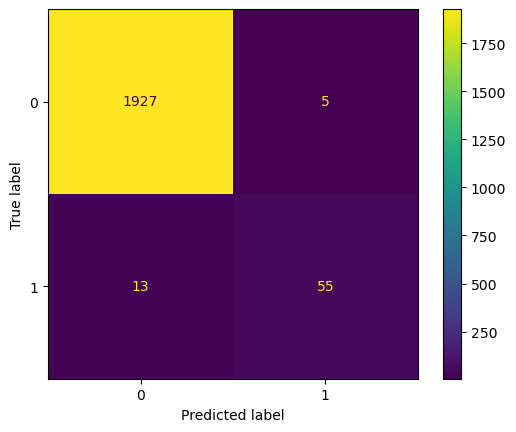

In [11]:
p_te = best.predict_proba(X_te)[:, 1]
pred = (p_te >= threshold).astype(int)

print("Test PR-AUC:", round(average_precision_score(y_te, p_te), 4))
print(classification_report(y_te, pred, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred)).plot()
plt.show()

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, precision_score, f1_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300,
        class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost (tuned)": best,
}
rows = []
for name, m in models.items():
    if name != "XGBoost (tuned)":
        m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    t = threshold if name == "XGBoost (tuned)" else 0.5
    yhat = (p >= t).astype(int)
    rows.append([name, average_precision_score(y_te, p),
                 precision_score(y_te, yhat), recall_score(y_te, yhat),
                 f1_score(y_te, yhat)])

import pandas as pd
print(pd.DataFrame(rows, columns=["Model","PR-AUC","Precision","Recall","F1"]).round(3))

                 Model  PR-AUC  Precision  Recall     F1
0  Logistic Regression   0.430      0.180   0.882  0.299
1        Random Forest   0.879      0.963   0.765  0.852
2      XGBoost (tuned)   0.907      0.917   0.809  0.859


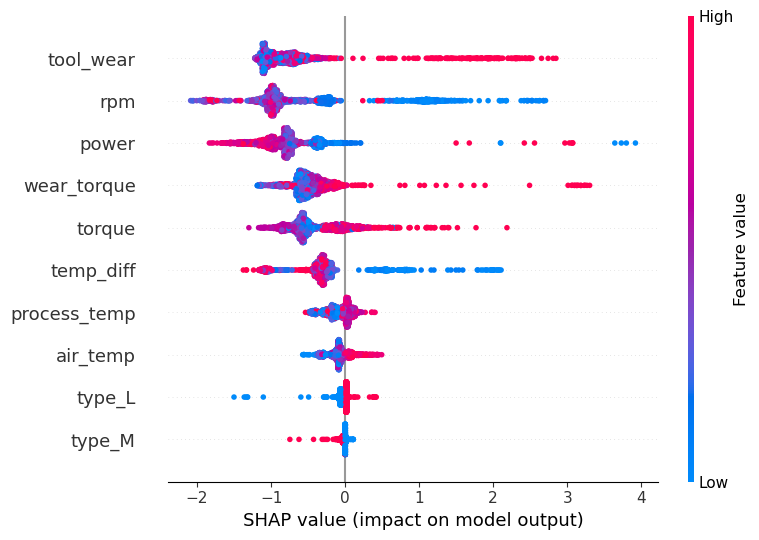

In [13]:
import shap

explainer = shap.TreeExplainer(best)
shap_values = explainer.shap_values(X_te)
shap.summary_plot(shap_values, X_te)

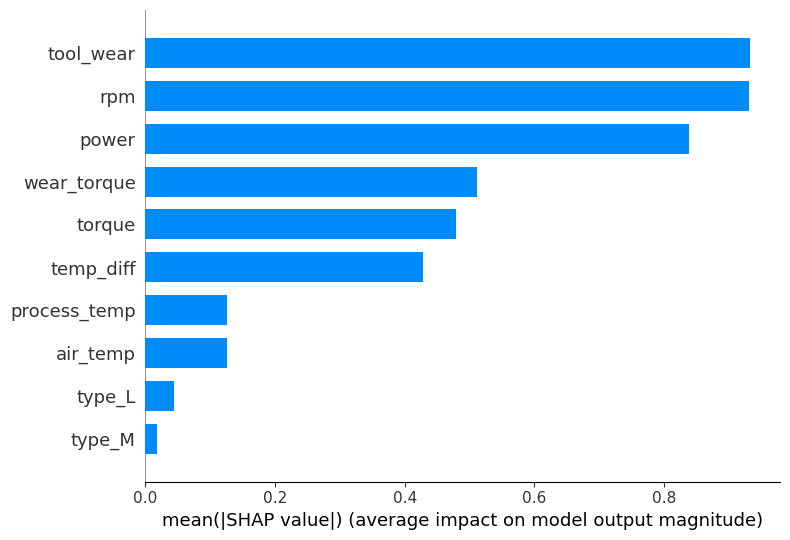

In [14]:
shap.summary_plot(shap_values, X_te, plot_type="bar")

In [15]:
import joblib
joblib.dump(best, "model.pkl")
joblib.dump(X.columns.tolist(), "columns.pkl")
joblib.dump(float(threshold), "threshold.pkl")
print(X.columns.tolist())

['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'temp_diff', 'power', 'wear_torque', 'type_L', 'type_M']


In [16]:
import os
print(os.getcwd())

C:\Users\subhr


In [17]:
%%writefile app.py
import streamlit as st, joblib, pandas as pd

model = joblib.load("model.pkl")
cols = joblib.load("columns.pkl")
threshold = joblib.load("threshold.pkl")

st.title("Machine Failure Predictor")
t = st.selectbox("Product type", ["L", "M", "H"])
air = st.number_input("Air temperature [K]", 290.0, 310.0, 300.0)
proc = st.number_input("Process temperature [K]", 300.0, 320.0, 310.0)
rpm = st.number_input("Rotational speed [rpm]", 1000, 3000, 1500)
torque = st.number_input("Torque [Nm]", 0.0, 100.0, 40.0)
wear = st.number_input("Tool wear [min]", 0, 300, 100)

if st.button("Predict"):
    row = {"air_temp": air, "process_temp": proc, "rpm": rpm,
           "torque": torque, "tool_wear": wear,
           "temp_diff": proc - air,
           "power": torque * rpm * 2 * 3.1416 / 60,
           "wear_torque": wear * torque,
           "type_L": int(t == "L"), "type_M": int(t == "M")}
    X_new = pd.DataFrame([row]).reindex(columns=cols, fill_value=0)
    prob = model.predict_proba(X_new)[0, 1]
    st.metric("Failure probability", f"{prob:.1%}")
    if prob >= threshold:
        st.error("High failure risk: schedule maintenance")
    else:
        st.success("Machine looks healthy")

Writing app.py


In [18]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\subhr
['-1.14-windows.xml', '.anaconda', '.bash_history', '.claude', '.claude.json', '.conda', '.condarc', '.continuum', '.copilot', '.eclipse', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.m2', '.matplotlib', '.ms-ad', '.p2', '.packettracer', '.python_history', '.redhat', '.vscode', '.vscode-shared', 'anaconda3', 'anaconda_projects', 'app.py', 'AppData', 'Application Data', 'Cisco Packet Tracer 9.0.1', 'columns.pkl', 'Contacts', 'Cookies', 'CrossDevice', 'Documents', 'Downloads', 'eclipse', 'Favorites', 'Links', 'Local Settings', 'MLproject.ipynb', 'model.pkl', 'Muse Hub', 'Music', 'My Documents', 'NetHood', 'New folder', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{3e31b1e4-f303-11ef-b65f-388d3d1d7aad}.TM.blf', 'NTUSER.DAT{3e31b1e4-f303-11ef-b65f-388d3d1d7aad}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{3e31b1e4-f303-11ef-b65f-388d3d1d7aad}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'On

In [19]:
import sklearn, xgboost, pandas, joblib, numpy
print(f"""pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
joblib=={joblib.__version__}
streamlit""")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
joblib==1.4.2
streamlit
